In [1]:
%load_ext autoreload
%autoreload 2

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import *
import os

from helpers import *
from Code.costs import *
from Code.implementations import *

from Code.Logistic_SGD import stochastic_logistic_regression_reg, cross_validation_logreg

In [6]:
data_path = "data/dataset"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

## Preprocessing

In [ ]:
nan_ratio = np.isnan(x_train).mean(axis=0)
mask = nan_ratio < 0.8
x_tr = x_train[:, mask]
x_te = x_test[:, mask]   

med = np.nanmedian(x_tr, axis=0)
x_tr = np.where(np.isnan(x_tr), med, x_tr)
x_te = np.where(np.isnan(x_te), med, x_te)

mean = x_tr.mean(axis=0)
std = x_tr.std(axis=0)
std[std == 0] = 1.0
x_tr = (x_tr - mean) / std
x_te = (x_te - mean) / std

y_tr = y_train

y_tr[y_tr==-1] = 0 # mapping for logistic regression


## Training model

In [28]:
w_zero = np.zeros(x_tr.shape[1])

w, loss = stochastic_logistic_regression_reg(y_train, x_tr, w_zero,batch_size=500, max_iters=200, gamma=0.02, lambda_=0)

SGD iter. 0/199: loss=0.6887768424984866, norm_w =0.018526558739902367
SGD iter. 1/199: loss=0.6827478691239723, norm_w =0.03259742419945478
SGD iter. 2/199: loss=0.6768163663386393, norm_w =0.04365326687273704
SGD iter. 3/199: loss=0.671809987509744, norm_w =0.05686169517752353
SGD iter. 4/199: loss=0.6680864651730212, norm_w =0.06919520554219472
SGD iter. 5/199: loss=0.6642286649659273, norm_w =0.07810657121384747
SGD iter. 6/199: loss=0.6595343062686154, norm_w =0.08947547506576312
SGD iter. 7/199: loss=0.6580417563863687, norm_w =0.09376829375772588
SGD iter. 8/199: loss=0.655707336863689, norm_w =0.09996489422175574
SGD iter. 9/199: loss=0.6527722140843047, norm_w =0.10548001875037148
SGD iter. 10/199: loss=0.649394046899955, norm_w =0.11588693445393816
SGD iter. 11/199: loss=0.6479644522666657, norm_w =0.1192409884371329
SGD iter. 12/199: loss=0.6449735053483951, norm_w =0.13089956206527156
SGD iter. 13/199: loss=0.6435485703186122, norm_w =0.13695735840323964
SGD iter. 14/199: l

In [38]:
from Code.helpers import build_k_indices
from plots import cross_validation_visualization


def cross_validation_logreg_demo(y, x, k_fold, gammas, max_iters, batch_size, lambda_):
    """cross validation over regularisation parameter lambda.

    Args:
        degree: integer, degree of the polynomial expansion
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """

    seed = 12
    k_fold = k_fold
    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []
    ### SOLUTION
    # cross validation
    for gamma in gammas:
        print("Computing gamma=", gamma, "----------------------------")
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            print("Computing gamma=", gamma, 'fold: ',k, "#######################")
            loss_tr, loss_te = cross_validation_logreg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_gamma, best_rmse = gammas[np.argmin(rmse_te)], np.min(rmse_te)
 

    cross_validation_visualization(gammas, rmse_tr, rmse_te)
    print(
        "For SGD, the choice of gamma which leads to the best test mse is %.5f with a test mse of %.3f"
        % (best_gamma, best_rmse)
    )
    return best_gamma, best_rmse

Computing gamma= 0.0001 ----------------------------
Computing gamma= 0.0001 fold:  0 #######################
SGD iter. 0/99: loss=0.693124388979858, norm_w =6.966162984470941e-05
SGD iter. 1/99: loss=0.6931013142180347, norm_w =0.00011417201219026539
SGD iter. 2/99: loss=0.6930771662449557, norm_w =0.00016074668811623754
SGD iter. 3/99: loss=0.693050069243254, norm_w =0.00021443252847603214
SGD iter. 4/99: loss=0.6930244790827983, norm_w =0.0002703756214246969
SGD iter. 5/99: loss=0.6929998034308829, norm_w =0.00031869888796073604
SGD iter. 6/99: loss=0.6929747654009212, norm_w =0.0003706114462463844
SGD iter. 7/99: loss=0.6929566365754052, norm_w =0.00040718285224896527
SGD iter. 8/99: loss=0.6929308104062663, norm_w =0.0004625138341618642
SGD iter. 9/99: loss=0.6929092506393365, norm_w =0.0005058712436947273
SGD iter. 10/99: loss=0.6928842499923201, norm_w =0.0005574507079719121
SGD iter. 11/99: loss=0.6928588522860275, norm_w =0.0006073479342155739
SGD iter. 12/99: loss=0.692833550

/Users/katiahaefliger/Desktop/EPFL/MA 3/Machine Learning/project1/ML_project1/Code/costs.py:22: RuntimeWarning: divide by zero encountered in log
  loss = y.T.dot(np.log(pred)) + (1 - y).T.dot(np.log(1 - pred))


SGD iter. 37/99: loss=0.2677358225584322, norm_w =2.109419189919401
SGD iter. 38/99: loss=0.26388211721837185, norm_w =2.1311572510848578
SGD iter. 39/99: loss=0.26127052182734695, norm_w =2.150349457374677
SGD iter. 40/99: loss=0.2591214280467482, norm_w =2.173304888528593
SGD iter. 41/99: loss=0.25846365989843134, norm_w =2.187729245783478
SGD iter. 42/99: loss=0.2599814709301516, norm_w =2.2057738286793906
SGD iter. 43/99: loss=0.2579960120841463, norm_w =2.2241703105376303
SGD iter. 44/99: loss=0.2583693509862663, norm_w =2.2370692962218457
SGD iter. 45/99: loss=0.2570245541667769, norm_w =2.2547228792120326
SGD iter. 46/99: loss=0.2555120581508859, norm_w =2.272159335979519
SGD iter. 47/99: loss=0.25798359490963335, norm_w =2.2939275368201497
SGD iter. 48/99: loss=0.25621637533742897, norm_w =2.311472293584946
SGD iter. 49/99: loss=0.2544197990251948, norm_w =2.3228729487868867
SGD iter. 50/99: loss=0.25265192795334995, norm_w =2.3310992916024817
SGD iter. 51/99: loss=0.2530723776

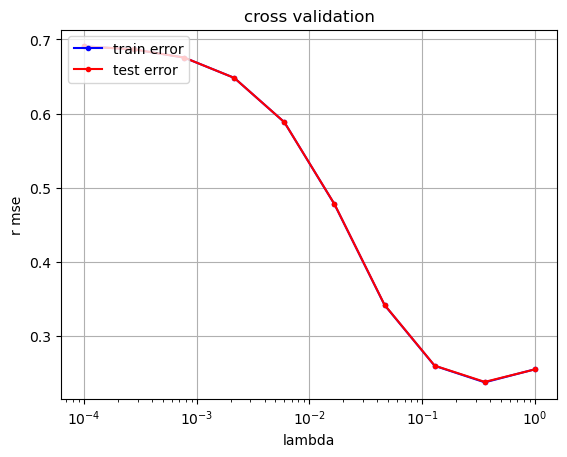

In [43]:
k_fold = 10
gammas = np.logspace(-4, 0, 10)
max_iters = 50
batch_size = 250

best_gamma, best_mse = cross_validation_logreg_demo(y_train, x_tr, k_fold=k_fold,batch_size=250, max_iters=100, gammas=gammas, lambda_=0)

# Final model training

In [ ]:
def best_gamma_lambda_selection(y,x, k_fold, gammas, max_iters, batch_size, lambdas, seed=1):
    """cross validation over regularisation parameter lambda and degree.

    Args:
        degrees: shape = (d,), where d is the number of degrees to test
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_degree : integer, value of the best degree
        best_lambda : scalar, value of the best lambda
        best_rmse : value of the rmse for the couple (best_degree, best_lambda)

    >>> best_degree_selection(np.arange(2,11), 4, np.logspace(-4, 0, 30))
    (7, 0.004520353656360241, 0.2895728056656946)
    """

    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)

    # for each degree, we compute the best lambdas and the associated rmse
    best_lambdas = []
    best_rmses = []

    # vary degree
    for gamma in gammas:
        print('################ Computing gamma: ', gamma, '###################')
        # cross validation
        rmse_te = []
        for lambda_ in lambdas:
            print(f'Computing gamma: {gamma} & lambda: {lambda_}-------------')
            rmse_te_tmp = []
            for k in range(k_fold):
                print(f'Computing gamma: {gamma} & lambda: {lambda_} FOLD {k} ||||||||||||')
                _, loss_te = cross_validation_logreg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
                rmse_te_tmp.append(loss_te)
            rmse_te.append(np.mean(rmse_te_tmp))

        ind_lambda_opt = np.argmin(rmse_te)
        best_lambdas.append(lambdas[ind_lambda_opt])
        best_rmses.append(rmse_te[ind_lambda_opt])

    ind_best_gamma = np.argmin(best_rmses)
    best_gamma = gammas[ind_best_gamma]
    best_lambda = best_lambdas[ind_best_gamma]
    best_rmse = best_rmses[ind_best_gamma]

    return float(best_gamma), float(best_lambda), float(best_rmse)

In [ ]:
k_fold = 10
gammas = np.logspace(-4, 0, 10)
lambdas = np.logspace(-4, 0, 10)
max_iters = 200
batch_size = 250

# will take some time to run :)
best_gamma, best_mse = best_gamma_lambda_selection(y_train, x_tr, k_fold=k_fold,batch_size=batch_size, max_iters=max_iters, gammas=gammas, lambdas=lambdas)